In [38]:
import tensorflow as tf
import numpy as np
import pandas as pd

df = pd.read_csv(
    "data/fra.txt",
    sep="\t",
    header=None,
    usecols=[0, 1],
    names=["english", "french"]
)

print(df.shape)
display(df.head())


print("Dataset shape:", df.shape)
display(df.head())


(240521, 2)


,english,french
0,Go.,Va !
1,Go.,Marche.
2,Go.,En route !
3,Go.,Bouge !
4,Hi.,Salut !


Dataset shape: (240521, 2)


,english,french
0,Go.,Va !
1,Go.,Marche.
2,Go.,En route !
3,Go.,Bouge !
4,Hi.,Salut !


In [39]:
df.isnull().sum()

english    0
french     0
dtype: int64

In [40]:
df.duplicated().sum()

np.int64(0)

In [41]:
df['en_length'] = df['english'].str.split().str.len()
df['fr_length'] = df['french'].str.split().str.len()

print(df['en_length'].describe())

count    240521.000000
mean          6.083473
std           2.467415
min           1.000000
25%           4.000000
50%           6.000000
75%           7.000000
max          55.000000
Name: en_length, dtype: float64


In [42]:
print(df['fr_length'].describe())

count    240521.000000
mean          6.632099
std           2.797527
min           1.000000
25%           5.000000
50%           6.000000
75%           8.000000
max          68.000000
Name: fr_length, dtype: float64


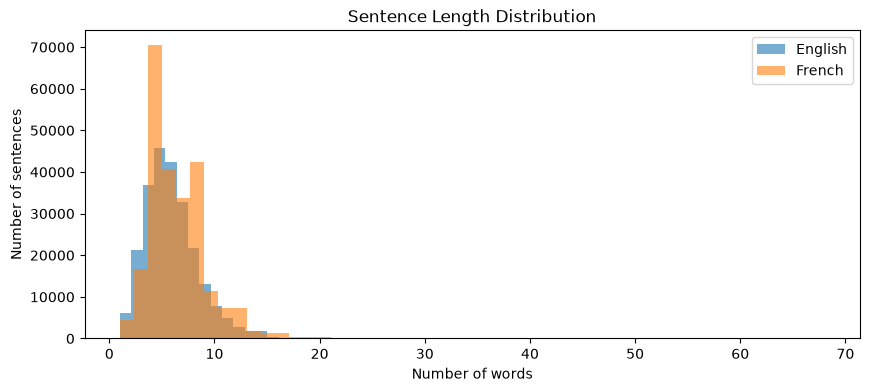

English 95th percentile: 11.0
French 95th percentile: 12.0


In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.hist(df["en_length"], bins=50, alpha=0.6, label="English")
plt.hist(df["fr_length"], bins=50, alpha=0.6, label="French")

plt.xlabel("Number of words")
plt.ylabel("Number of sentences")
plt.title("Sentence Length Distribution")
plt.legend()
plt.show()

print("English 95th percentile:", df["en_length"].quantile(0.95))
print("French 95th percentile:", df["fr_length"].quantile(0.95))


In [44]:
from sklearn.model_selection import train_test_split
df['english'] = df['english'].str.strip()
df['french'] = df['french'].str.strip()

train_df , temp_df = train_test_split(df, test_size=0.2 , random_state=42)
val_df , test_df = train_test_split(temp_df,test_size=0.2 , random_state=42)

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(192416, 4)
(38484, 4)
(9621, 4)


## ENGLISH TOKENIZER

In [45]:
from tokenizers import Tokenizer , models , trainers , pre_tokenizers
en_tokenizer = Tokenizer(models.BPE(unk_token = "[UNK]"))

en_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
trainer = trainers.BpeTrainer(vocab_size=8000 , special_tokens=["[PAD]" , "[UNK]" , "[START]" , '[END]'])

en_tokenizer.train_from_iterator(train_df['english'].tolist(), trainer= trainer)

sentence = 'I love machine learning'
encoded = en_tokenizer.encode(sentence)

print(encoded.tokens)
print(encoded.ids)
print(en_tokenizer.get_vocab_size())




['I', 'love', 'machine', 'learning']
[36, 415, 2100, 2649]
8000


## FRENCH TOKENIZER

In [46]:
fr_tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))
fr_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()

fr_trainer = trainers.BpeTrainer(
    vocab_size=8000,
    special_tokens=["[PAD]", "[UNK]", "[START]", "[END]"]
)

fr_tokenizer.train_from_iterator(
    train_df["french"].tolist(),
    trainer=fr_trainer
)

sentence = "Je suis étudiant"

encoded = fr_tokenizer.encode(sentence)

print("Tokens:", encoded.tokens)
print("Token IDs:", encoded.ids)
print("Vocabulary size:", fr_tokenizer.get_vocab_size())





Tokens: ['Je', 'suis', 'étudiant']
Token IDs: [129, 190, 2025]
Vocabulary size: 8000


In [47]:
def prepare_pair(english, french):

    en_ids = en_tokenizer.encode(english).ids
    fr_ids = fr_tokenizer.encode(french).ids


    en_end = en_tokenizer.token_to_id("[END]")
    fr_start = fr_tokenizer.token_to_id("[START]")
    fr_end = fr_tokenizer.token_to_id("[END]")
    encoder_input = en_ids + [en_end]


    decoder_input = [fr_start] + fr_ids
    decoder_target = fr_ids + [fr_end]

    return encoder_input, decoder_input, decoder_target

english = "I am happy"
french = "Je suis heureux"

enc, dec, target = prepare_pair(english, french)

print("Encoder input:", enc)
print("Decoder input:", dec)
print("Decoder target:", target)


Encoder input: [36, 225, 498, 3]
Decoder input: [2, 129, 190, 738]
Decoder target: [129, 190, 738, 3]


In [48]:
MAX_LEN = 32

en_lengths = train_df["english"].apply(
    lambda text: len(en_tokenizer.encode(text).ids) + 1
)

fr_lengths = train_df["french"].apply(
    lambda text: len(fr_tokenizer.encode(text).ids) + 1
)
fits = (en_lengths <= MAX_LEN) & (fr_lengths <= MAX_LEN)

print("Total training pairs:", len(train_df))
print("Pairs within limit:", fits.sum())
print("Percentage retained:", round(fits.mean() * 100, 2), "%")

print("English 95th percentile:", en_lengths.quantile(0.95))
print("French 95th percentile:", fr_lengths.quantile(0.95))


Total training pairs: 192416
Pairs within limit: 192236
Percentage retained: 99.91 %
English 95th percentile: 14.0
French 95th percentile: 17.0


## PADDING TO GIVE IN THE ENCODER AND DECODER


In [49]:
from tensorflow.keras.utils import pad_sequences

def prepare_dataset(dataframe):
    encoder_inputs = []
    decoder_inputs = []
    decoder_targets = []

    for english, french in zip(
        dataframe["english"], dataframe["french"]
    ):
        enc, dec, target = prepare_pair(english, french)

        if len(enc) > MAX_LEN or len(dec) > MAX_LEN:
            continue

        encoder_inputs.append(enc)
        decoder_inputs.append(dec)
        decoder_targets.append(target)

    encoder_inputs = pad_sequences(
        encoder_inputs, maxlen=MAX_LEN, padding="post"
    )

    decoder_inputs = pad_sequences(
        decoder_inputs, maxlen=MAX_LEN, padding="post"
    )

    decoder_targets = pad_sequences(
        decoder_targets, maxlen=MAX_LEN, padding="post"
    )

    return encoder_inputs, decoder_inputs, decoder_targets



X_train, Y_train_in, Y_train_out = prepare_dataset(train_df)

print("Encoder shape:", X_train.shape)
print("Decoder input shape:", Y_train_in.shape)
print("Decoder target shape:", Y_train_out.shape)


Encoder shape: (192236, 32)
Decoder input shape: (192236, 32)
Decoder target shape: (192236, 32)


In [50]:
X_val, Y_val_in, Y_val_out = prepare_dataset(val_df)
X_test, Y_test_in, Y_test_out = prepare_dataset(test_df)


print("Validation:")
print(X_val.shape, Y_val_in.shape, Y_val_out.shape)

print("\nTest:")
print(X_test.shape, Y_test_in.shape, Y_test_out.shape)


Validation:
(38449, 32) (38449, 32) (38449, 32)

Test:
(9613, 32) (9613, 32) (9613, 32)


## EMBEDDING LAYER MAKING

In [51]:
D_MODEL = 128

EN_VOCAB_SIZE = en_tokenizer.get_vocab_size()
FR_VOCAB_SIZE = fr_tokenizer.get_vocab_size()

en_embedding = tf.keras.layers.Embedding(
    input_dim=EN_VOCAB_SIZE,
    output_dim=D_MODEL
)

fr_embedding = tf.keras.layers.Embedding(
    input_dim=FR_VOCAB_SIZE,
    output_dim=D_MODEL
)



## SINUSODIAL POSITIONAL ENCODING (sin even , cos odd , then add)

In [52]:
def positional_encoding(max_len, d_model):

    positions = np.arange(max_len)[:, np.newaxis]
    dimensions = np.arange(d_model)[np.newaxis, :]

    angles = positions / np.power(
        10000,
        (2 * (dimensions // 2)) / d_model
    )

    pe = np.zeros((max_len, d_model))

    pe[:, 0::2] = np.sin(angles[:, 0::2])
    pe[:, 1::2] = np.cos(angles[:, 1::2])

    return tf.constant(pe, dtype=tf.float32)


PE = positional_encoding(MAX_LEN, D_MODEL)

print("Positional encoding shape:", PE.shape)
print("Position 0, first 6 values:", PE[0, :6].numpy())
print("Position 1, first 6 values:", PE[1, :6].numpy())


Positional encoding shape: (32, 128)
Position 0, first 6 values: [0. 1. 0. 1. 0. 1.]
Position 1, first 6 values: [0.84147096 0.5403023  0.7617204  0.6479059  0.68156135 0.731761  ]


## ATTENTION CALCULATION FUNCTION 

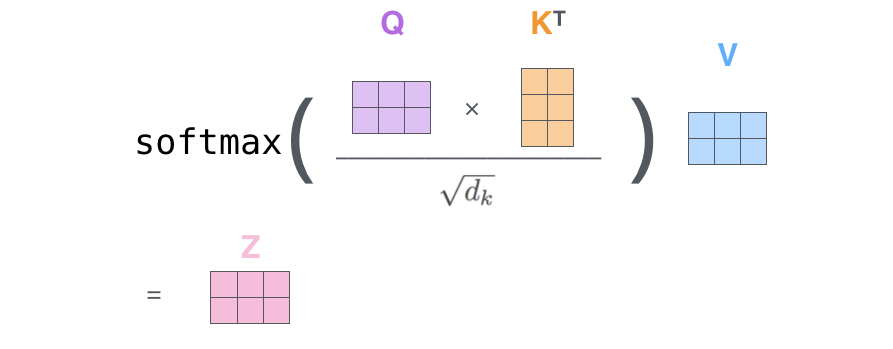

In [53]:
def scaled_dot_product_attention(q, k, v, mask=None):

    scores = tf.matmul(q, k, transpose_b=True)
    dk = tf.cast(tf.shape(k)[-1], tf.float32)
    scores = scores / tf.math.sqrt(dk)

    if mask is not None:
        scores += mask * -1e9


    weights = tf.nn.softmax(scores, axis=-1)
    output = tf.matmul(weights, v)

    return output, weights


## MUTLI HEAD ATTENTIONCLASS

In [54]:
class MultiHeadAttention(tf.keras.layers.Layer):
    def __init__(self , d_model = 128 , num_heads = 4):
        super().__init__()
        self.num_heads = num_heads
        self.depth = d_model // num_heads
        
        self.wq = tf.keras.layers.Dense(d_model)
        self.wk = tf.keras.layers.Dense(d_model)
        self.wv = tf.keras.layers.Dense(d_model)
        
        
        self.dense = tf.keras.layers.Dense(d_model)
        
    def split_heads(self , x):
        batch_size = tf.shape(x)[0]
        seq_len = tf.shape(x)[1]
        
        x = tf.reshape(x , (batch_size , seq_len , self.num_heads , self.depth))
        return tf.transpose(x, perm = [ 0,2,1,3])
    
    def call(self, q, k , v , mask = None):
        q = self.wq(q)
        k = self.wk(k)
        v = self.wv(v)
        
        q = self.split_heads(q)
        k = self.split_heads(k)
        v = self.split_heads(v)
        
        attention, weights = scaled_dot_product_attention(q, k, v, mask)
        
        attention = tf.transpose(attention , perm=[0,2,1,3])
        batch_size =tf.shape(attention)[0]
        seq_len = tf.shape(attention)[1]
        
        attention = tf.reshape(
            attention,
            (batch_size, seq_len, self.num_heads * self.depth)
        )
        output = self.dense(attention)
        
        return output,weights

## FEED FORWARD NN

In [55]:
def feed_forward_network(d_model=128, dff=512):

    return tf.keras.Sequential([
        tf.keras.layers.Dense(dff, activation="relu"),
        tf.keras.layers.Dense(d_model)
    ])


ffn = feed_forward_network()

sample = tf.random.normal((2, 32, 128))

output = ffn(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)


Input shape: (2, 32, 128)
Output shape: (2, 32, 128)


## ENCODER LAYER

In [56]:
class EncoderLayer(tf.keras.layers.Layer):

    def __init__(self, d_model=128, num_heads=4, dff=512, dropout_rate=0.1):
        super().__init__()

        self.mha = MultiHeadAttention(d_model, num_heads)
        self.ffn = feed_forward_network(d_model, dff)

        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = tf.keras.layers.Dropout(dropout_rate)
        self.dropout2 = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, mask=None, training=False):
        attention_output, _ = self.mha(x, x, x, mask)
        
        attention_output = self.dropout1(attention_output, training=training)
        x = self.norm1(x + attention_output)
        
        ffn_output = self.ffn(x)
        ffn_output = self.dropout2( ffn_output, training=training)
        
        x = self.norm2(x + ffn_output)

        return x


In [57]:
class Encoder(tf.keras.layers.Layer):

    def __init__(self, d_model=128,
                 num_heads=4, dff=512,
                 num_layers=2, dropout_rate=0.1):
        super().__init__()

        self.d_model = d_model

        self.embedding = en_embedding
        self.pos_encoding = PE

        self.encoder_layers = [
            EncoderLayer(d_model, num_heads, dff, dropout_rate)
            for _ in range(num_layers)
        ]

        self.dropout = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, training=False):
        mask = tf.cast(tf.equal(x, 0), tf.float32)
        mask = mask[:, tf.newaxis, tf.newaxis, :]
        x = self.embedding(x)
        x = x * tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x = x + self.pos_encoding[tf.newaxis, :tf.shape(x)[1], :]

        x = self.dropout(x, training=training)
        for layer in self.encoder_layers:
            x = layer(x, mask=mask, training=training)

        return x


## DECODER PART

# Why masking ? To avoid data leakage while training , cause during inference the decoder cant see the future tokens 

In [58]:
def create_decoder_mask(x):

    length = tf.shape(x)[1]

    future_mask = 1 - tf.linalg.band_part(
        tf.ones((length, length)), -1, 0
    )

    pad_mask = tf.cast(x == 0, tf.float32)
    mask = tf.maximum(
        future_mask[None, None, :, :],
        pad_mask[:, None, None, :]
    )
    return mask

In [59]:
class DecoderLayer(tf.keras.layers.Layer):

    def __init__(self, d_model=128, num_heads=4,
                 dff=512, dropout_rate=0.1):
        super().__init__()

        self.mha1 = MultiHeadAttention(d_model, num_heads)
        self.mha2 = MultiHeadAttention(d_model, num_heads)

        self.ffn = feed_forward_network(d_model, dff)

        self.norm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.norm3 = tf.keras.layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = tf.keras.layers.Dropout(dropout_rate)
        self.dropout2 = tf.keras.layers.Dropout(dropout_rate)
        self.dropout3 = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, encoder_output, look_ahead_mask,
             padding_mask, training=False):
        # masked multi head attettion
        attn1, _ = self.mha1(x, x, x, look_ahead_mask)
        attn1 = self.dropout1(attn1, training=training)
        x = self.norm1(x + attn1)
        #cross attention
        attn2, _ = self.mha2(
            x, encoder_output, encoder_output, padding_mask
        )
        attn2 = self.dropout2(attn2, training=training)
        x = self.norm2(x + attn2)
        #feed forward network
        ffn_output = self.ffn(x)
        ffn_output = self.dropout3(ffn_output, training=training)
        x = self.norm3(x + ffn_output)

        return x


In [60]:
class Decoder(tf.keras.layers.Layer):

    def __init__(self, d_model=128, num_heads=4,
                 dff=512, num_layers=2, dropout_rate=0.1):
        super().__init__()
        self.d_model = d_model
        self.embedding = fr_embedding
        self.pos_encoding = PE

        self.decoder_layers = [
            DecoderLayer(d_model, num_heads, dff, dropout_rate)
            for _ in range(num_layers)
        ]

        self.dropout = tf.keras.layers.Dropout(dropout_rate)

    def call(self, x, encoder_output, encoder_input,
             training=False):
        look_ahead_mask = create_decoder_mask(x)

        # padding
        padding_mask = tf.cast(
            tf.equal(encoder_input, 0), tf.float32
        )
        padding_mask = padding_mask[:, None, None, :]

        # french embeddings
        x = self.embedding(x)

        x = x * tf.math.sqrt(tf.cast(self.d_model, tf.float32))
        x = x + self.pos_encoding[None, :tf.shape(x)[1], :]

        x = self.dropout(x, training=training)

        # Pass through both decoder layers
        for layer in self.decoder_layers:
            x = layer(
                x,
                encoder_output,
                look_ahead_mask,
                padding_mask,
                training=training
            )

        return x


## TRANSFORMER

In [61]:
class Transformer(tf.keras.Model):

    def __init__(self, encoder, decoder, vocab_size):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.final_layer = tf.keras.layers.Dense(vocab_size)

    def call(self, inputs, training=False):

        english, french = inputs
        encoder_output = self.encoder(english, training=training)
        
        decoder_output = self.decoder(french, encoder_output, english,training=training)
        logits = self.final_layer(decoder_output)

        return logits

encoder = Encoder()
decoder = Decoder()
transformer = Transformer(
    encoder,
    decoder,
    FR_VOCAB_SIZE
)


## CROSS ENTROPY LOSS ONLY FOR NOT MASKED

In [62]:
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True,reduction="none")

def masked_loss(y_true, y_pred):

    loss = loss_object(y_true, y_pred)
    mask = tf.cast(y_true != 0, tf.float32)

    loss = loss * mask
    return tf.reduce_sum(loss) / tf.reduce_sum(mask)


In [63]:
class TransformerSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):

    def __init__(self, d_model=128, warmup_steps=4000):
        super().__init__()

        self.d_model = tf.cast(d_model, tf.float32)
        self.warmup_steps = warmup_steps

    def __call__(self, step):

        step = tf.cast(step, tf.float32)

        arg1 = tf.math.rsqrt(tf.maximum(step, 1.0))
        arg2 = step * (self.warmup_steps ** -1.5)

        return tf.math.rsqrt(self.d_model) * tf.minimum(arg1, arg2)


learning_rate = TransformerSchedule(D_MODEL)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate,
    beta_1=0.9,
    beta_2=0.98,
    epsilon=1e-9
)
# transformers can be seensitive to large updates in early training thats why gradually do warm steps to increase lr

In [64]:
BATCH_SIZE = 32

train_dataset = tf.data.Dataset.from_tensor_slices(
    ((X_train, Y_train_in), Y_train_out)
)

train_dataset = (
    train_dataset
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    ((X_val, Y_val_in), Y_val_out)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


In [65]:
def masked_accuracy(y_true, y_pred):

    predictions = tf.argmax(
        y_pred, axis=-1, output_type=tf.int32
    )

    y_true = tf.cast(y_true, tf.int32)
    correct = tf.equal(y_true, predictions)
    mask = tf.not_equal(y_true, 0)

    correct = tf.logical_and(correct, mask)

    return (
        tf.reduce_sum(tf.cast(correct, tf.float32))
        / tf.reduce_sum(tf.cast(mask, tf.float32))
    )


transformer.compile(
    optimizer=optimizer,
    loss=masked_loss,
    metrics=[masked_accuracy]
)
# accuracy for only the tokens needed


print("Optimizer:", transformer.optimizer)
print("Loss:", transformer.loss)
print("Metrics:", transformer.metrics_names)

Optimizer: <keras.src.optimizers.adam.Adam object at 0x7ac20226cc80>
Loss: <function masked_loss at 0x7ac203213560>
Metrics: ['loss', 'compile_metrics']


In [66]:
import os

os.makedirs("checkpoints", exist_ok=True)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath="checkpoints/transformer_epoch_{epoch:02d}.weights.h5",
    save_weights_only=True,
    save_freq="epoch",
    verbose=1
)

history = transformer.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5,
    callbacks=[checkpoint_callback]
)



Epoch 1/5


/home/codewithdeep/venvs/tensorflow-gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/home/codewithdeep/venvs/tensorflow-gpu/lib/python3.12/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'encoder_layer_2' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/codewithdeep/venvs/tensorflow-gpu/lib/python3.12/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'encoder_layer_3' (of type EncoderLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy th

6005/6008 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 3.1782 - masked_accuracy: 0.5082

W0000 00:00:1794495682.883239   19845 assert_op.cc:39] Ignoring Assert operator compile_loss/masked_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1794495685.262583   19845 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_32767__.226
I0000 00:00:1794495690.090769   21481 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_202', 64 bytes spill stores, 32 bytes spill loads

I0000 00:00:1794495692.022721   21483 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7', 188 bytes spill stores, 180 bytes spill loads

I0000 00:00:1794495693.259091   21492 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_244', 8772 bytes spill stores, 8764 bytes spill loads

I0000 00:00:1794495705.707490   21486 subprocess_c

6008/6008 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 3.1778 - masked_accuracy: 0.5083

W0000 00:00:1794495740.124747   19845 assert_op.cc:39] Ignoring Assert operator compile_loss/masked_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1794495740.215362   19845 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_59178__.105
W0000 00:00:1794495755.392507   19840 assert_op.cc:39] Ignoring Assert operator compile_loss/masked_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1794495755.456906   19840 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_59178__.105
I0000 00:00:1794495756.940023   21889 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_154', 8964 bytes spill stores, 9040 bytes spill loads




Epoch 1: saving model to checkpoints/transformer_epoch_01.weights.h5

Epoch 1: finished saving model to checkpoints/transformer_epoch_01.weights.h5
6008/6008 ━━━━━━━━━━━━━━━━━━━━ 284s 29ms/step - loss: 3.1778 - masked_accuracy: 0.5083 - val_loss: 1.8883 - val_masked_accuracy: 0.6671
Epoch 2/5
6008/6008 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.7608 - masked_accuracy: 0.6845
Epoch 2: saving model to checkpoints/transformer_epoch_02.weights.h5

Epoch 2: finished saving model to checkpoints/transformer_epoch_02.weights.h5
6008/6008 ━━━━━━━━━━━━━━━━━━━━ 103s 17ms/step - loss: 1.7608 - masked_accuracy: 0.6845 - val_loss: 1.5425 - val_masked_accuracy: 0.7207
Epoch 3/5
6007/6008 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.5240 - masked_accuracy: 0.7211
Epoch 3: saving model to checkpoints/transformer_epoch_03.weights.h5

Epoch 3: finished saving model to checkpoints/transformer_epoch_03.weights.h5
6008/6008 ━━━━━━━━━━━━━━━━━━━━ 103s 17ms/step - loss: 1.5240 - masked_accuracy: 0.7211 - val_

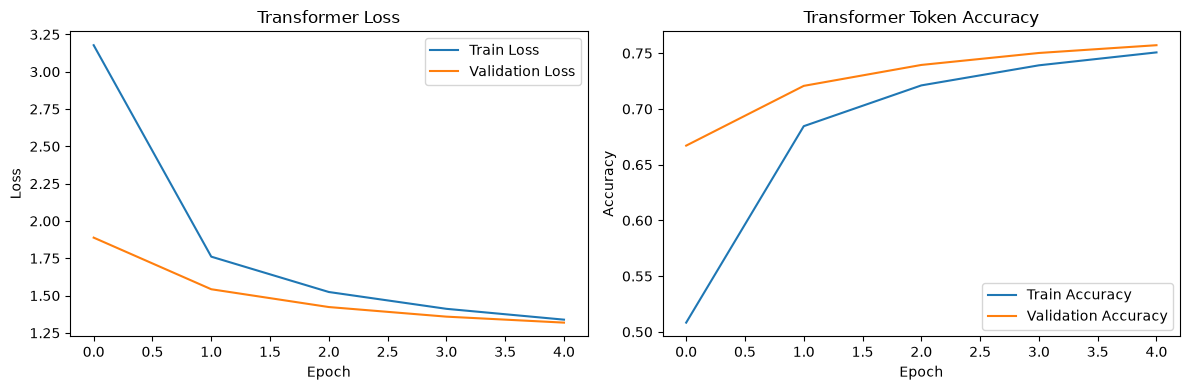

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Loss")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history["masked_accuracy"], label="Train Accuracy")
plt.plot(history.history["val_masked_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Transformer Token Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


## EVALUATION

In [ ]:
print("Final Train Loss:", history.history["loss"][-1])
print("Final Validation Loss:", history.history["val_loss"][-1])

print("Final Train Accuracy:", history.history["masked_accuracy"][-1])
print("Final Validation Accuracy:", history.history["val_masked_accuracy"][-1])


Final Train Loss: 1.3386963605880737
Final Validation Loss: 1.3187925815582275
Final Train Accuracy: 0.7507219910621643
Final Validation Accuracy: 0.7571797966957092


In [69]:
test_dataset = tf.data.Dataset.from_tensor_slices(
    ((X_test, Y_test_in), Y_test_out)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_loss, test_accuracy = transformer.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

296/301 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.3154 - masked_accuracy: 0.7570

W0000 00:00:1794496290.651166   19844 assert_op.cc:39] Ignoring Assert operator compile_loss/masked_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1794496290.738143   19844 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_59178__.105
I0000 00:00:1794496296.035111   23330 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_154', 8964 bytes spill stores, 9040 bytes spill loads



301/301 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - loss: 1.3157 - masked_accuracy: 0.7570
Test Loss: 1.3157
Test Accuracy: 75.70%


## GREEDY

In [71]:
import sacrebleu

def translate_greedy(sentence):

    # English tokens + END
    en_ids = en_tokenizer.encode(sentence).ids[:MAX_LEN - 1]
    en_ids.append(en_tokenizer.token_to_id("[END]"))

    # Pad English input
    en_ids += [0] * (MAX_LEN - len(en_ids))
    english = tf.constant([en_ids], dtype=tf.int32)

    # French generation begins with START
    start_id = fr_tokenizer.token_to_id("[START]")
    end_id = fr_tokenizer.token_to_id("[END]")

    french_ids = [start_id]

    for _ in range(MAX_LEN - 1):

        # Pad current French tokens
        decoder_ids = french_ids + [0] * (MAX_LEN - len(french_ids))
        french = tf.constant([decoder_ids], dtype=tf.int32)

        # Predict next French token
        logits = transformer((english, french), training=False)

        next_id = int(
            tf.argmax(logits[0, len(french_ids) - 1]).numpy()
        )

        if next_id == end_id:
            break

        french_ids.append(next_id)

    return fr_tokenizer.decode(
        french_ids[1:],
        skip_special_tokens=True
    )


# Quick translation test
print(translate_greedy("I love you."))
print(translate_greedy("Where are you going?"))


Je t ' aime .
Où vas - tu ?


In [72]:
sample = test_df.sample(n=100, random_state=42)

references = sample["french"].tolist()

greedy_predictions = [
    translate_greedy(sentence)
    for sentence in sample["english"]
]

greedy_bleu = sacrebleu.corpus_bleu(
    greedy_predictions,
    [references]
)

print(f"Greedy BLEU: {greedy_bleu.score:.2f}")


Greedy BLEU: 19.81


## BEAM SEARCH

In [ ]:
def translate_beam(sentence, beam_width=4, alpha=0.6):

    en_ids = en_tokenizer.encode(sentence).ids[:MAX_LEN - 1]
    en_ids.append(en_tokenizer.token_to_id("[END]"))
    en_ids += [0] * (MAX_LEN - len(en_ids))

    english = tf.constant([en_ids], dtype=tf.int32)

    start_id = fr_tokenizer.token_to_id("[START]")
    end_id = fr_tokenizer.token_to_id("[END]")

    beams = [([start_id], 0.0, False)]

    def normalized_score(beam):
        tokens, score, finished = beam
        length = max(1, len(tokens) - 1)
        penalty = ((5 + length) / 6) ** alpha
        return score / penalty

    for _ in range(MAX_LEN - 1):

        candidates = []

        for tokens, score, finished in beams:

            if finished:
                candidates.append((tokens, score, True))
                continue

            decoder_ids = tokens + [0] * (MAX_LEN - len(tokens))
            french = tf.constant([decoder_ids], dtype=tf.int32)

            logits = transformer((english, french), training=False)
            log_probs = tf.nn.log_softmax(
                logits[0, len(tokens) - 1]
            )
            top_values, top_indices = tf.math.top_k(
                log_probs, k=beam_width
            )

            for token_id, log_prob in zip(
                top_indices.numpy(),
                top_values.numpy()
            ):
                token_id = int(token_id)

                new_tokens = tokens + [token_id]
                new_score = score + float(log_prob)
                is_finished = token_id == end_id

                candidates.append(
                    (new_tokens, new_score, is_finished)
                )

        beams = sorted(
            candidates,
            key=normalized_score,
            reverse=True
        )[:beam_width]

        if all(finished for _, _, finished in beams):
            break

    best_tokens = max(beams, key=normalized_score)[0]

    return fr_tokenizer.decode(
        best_tokens[1:],
        skip_special_tokens=True
    )



In [ ]:
print("Greedy:", translate_greedy("I love you."))
print("Beam:  ", translate_beam("I love you."))

print("Greedy:", translate_greedy("Where are you going?"))
print("Beam:  ", translate_beam("Where are you going?"))


Greedy: Je t ' aime .
Beam:   Je t ' aime bien .
Greedy: Où vas - tu ?
Beam:   Où vas - tu ?


In [79]:
print(translate_beam('How are you'))

Comment vas - tu .


In [75]:
beam_predictions = [
    translate_beam(sentence)
    for sentence in sample["english"]
]

beam_bleu = sacrebleu.corpus_bleu(
    beam_predictions,
    [references]
)

print(f"Greedy BLEU: {greedy_bleu.score:.2f}")
print(f"Beam BLEU:   {beam_bleu.score:.2f}")

print(f"Difference:  {beam_bleu.score - greedy_bleu.score:+.2f}")


Greedy BLEU: 19.81
Beam BLEU:   22.90
Difference:  +3.08


In [80]:
print(f"Total parameters: {transformer.count_params():,}")

trainable = sum(
    int(tf.size(w).numpy())
    for w in transformer.trainable_weights
)

print(f"Trainable parameters: {trainable:,}")

Total parameters: 4,005,696
Trainable parameters: 4,005,696
